# Finite differences for boundary value problems in Python

We approximate $y''=f(x,y,y')$ on $[a,b]$ with conditions
$\alpha y'+\beta y=\gamma$ at the two ends. We will derive the equations,
solve a nonlinear Robin problem with Newton and Crout, and check the error
against an exact solution. Install the repository with `pip install -e '.[notebooks]'`
and run all cells from the repository root.

Prerequisites: derivatives, Taylor series, linear systems and NumPy arrays.
[Full theory](https://metodosnumericos.jonramos.dev/en/articulos/frontera-diferencias-finitas/)
· [Guía en español](../docs/diferencias-finitas.es.md).

## 1. Mesh and central formulas

With $n$ subintervals, $h=(b-a)/n$ and $x_i=a+ih$, there are $n+1$ nodes.
Writing Taylor through the cubic terms leaves an $O(h^4)$ remainder. Subtracting
the two expansions isolates the first derivative; adding cancels the odd powers:

$$y'(x_i)=\frac{y(x_i+h)-y(x_i-h)}{2h}+O(h^2),$$
$$y(x_i+h)+y(x_i-h)=2y(x_i)+h^2y''(x_i)+O(h^4).$$

Subtract $2y(x_i)$ from both sides and divide by $h^2$ to obtain

$$y''(x_i)=\frac{y(x_i+h)-2y(x_i)+y(x_i-h)}{h^2}+O(h^2).$$

For the unknown nodal values, use the scaled residual

$$F_i=2y_i-y_{i-1}-y_{i+1}+h^2 f(x_i,y_i,(y_{i+1}-y_{i-1})/(2h)).$$

A small algebraic residual is not a bound on the continuous solution error.

## 2. Robin conditions and ghost nodes

The derivative coefficient is $\alpha$. If $\alpha\ne0$, centered differences give

$$y_{-1}=y_1+2h\frac{\beta_a}{\alpha_a}y_0-2h\frac{\gamma_a}{\alpha_a},$$
$$y_{n+1}=y_{n-1}-2h\frac{\beta_b}{\alpha_b}y_n+2h\frac{\gamma_b}{\alpha_b}.$$

Substitute these auxiliary values into the endpoint ODE equations, assuming a smooth
extension to the endpoints. They are not additional final unknowns. For Dirichlet
($\alpha=0$), fix the endpoint value through its own row instead.

## 3. Nonlinear example

$$y''=xyy'-3y^2+6x,\quad 3y(0)-2y'(0)=0,\quad 2y(1)-y'(1)/3=1.$$

Interior equations are

$$F_i=2y_i-y_{i-1}-y_{i+1}+\frac{hx_i}{2}y_i(y_{i+1}-y_{i-1})-3h^2y_i^2+6h^2x_i.$$

The ghost values are $y_{-1}=y_1-3hy_0$ and
$y_{n+1}=y_{n-1}+12hy_n-6h$. After substitution:

$$F_0=(2+3h)y_0-2y_1-3h^2y_0^2,$$
$$F_n=-2y_{n-1}+(2-12h)y_n+3h^2y_n^2-3h^2y_n+6h+6h^2.$$

Newton solves $J\Delta y=-F$ and updates $y\leftarrow y+\Delta y$.
The interior Jacobian entries are

$$J_{i,i-1}=-1-hx_i y_i/2,\quad
J_{i,i}=2+hx_i(y_{i+1}-y_{i-1})/2-6h^2y_i,\quad
J_{i,i+1}=-1+hx_i y_i/2.$$

The endpoint entries are $J_{0,0}=2+3h-6h^2y_0$, $J_{0,1}=-2$,
$J_{n,n-1}=-2$ and $J_{n,n}=2-12h+6h^2y_n-3h^2$.
Crout factors each tridiagonal Jacobian as $LU$ with unit diagonal in $U$;
forward and backward substitution give the Newton correction in linear work.
[Read the implementation](../bvp/linalg.py). It does not pivot.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bvp import Robin, nonlinear_finite_difference, linear_finite_difference

left, right = Robin(-2, 3, 0), Robin(-1/3, 2, 1)
def f(x, y, dy): return x*y*dy-3*y*y+6*x
def fy(x, y, dy): return x*dy-6*y
def fdy(x, y, dy): return x*y

def solve(n):
    return nonlinear_finite_difference(f, fy, fdy, 0, 1, left, right,
        initial=lambda x: .75*x*x, n=n)

result = solve(80)
assert result.converged
display(pd.DataFrame(result.history))
print('Scaled residual:', result.residual_norm)

,iteration,step_norm,residual_norm
0,1,2.478612e-01,1.843055e-01
1,2,2.338538e-03,1.765733e-05
2,3,2.201590e-06,1.489572e-11
3,4,2.433123e-12,1.312145e-12


Scaled residual: 1.3121448372288567e-12


The initial guess $g=3x^2/4$ satisfies both continuous Robin conditions:
$g(0)=g'(0)=0$ and $2g(1)-g'(1)/3=1$. It does not satisfy the ODE.
`tol` controls the relative/absolute Newton correction;
`residual_tol` controls $\|F\|_\infty/h^2$ after the update.
Both conditions must pass. `max_iter` limits the iteration count.

## 4. Last ten nodes and exact-solution check

The last ten indices are 71 through 80. Verify $y_*=x^3$ by substitution:
$y_*''-xy_*y_*'+3y_*^2=6x-3x^6+3x^6=6x$, and both boundary conditions hold.
We use it to measure error, not as the initial Newton guess.

,i,x,finite_difference,exact,abs_error
0,71,0.8875,0.699068,0.699045,0.000023
1,72,0.9000,0.729023,0.729000,0.000023
2,73,0.9125,0.759821,0.759799,0.000022
3,74,0.9250,0.791475,0.791453,0.000021
4,75,0.9375,0.823995,0.823975,0.000021
5,76,0.9500,0.857395,0.857375,0.000020
6,77,0.9625,0.891685,0.891666,0.000019
7,78,0.9750,0.926878,0.926859,0.000019
8,79,0.9875,0.962985,0.962967,0.000018
9,80,1.0000,1.000017,1.000000,0.000017


Maximum nodal error: 7.024513029110015e-05


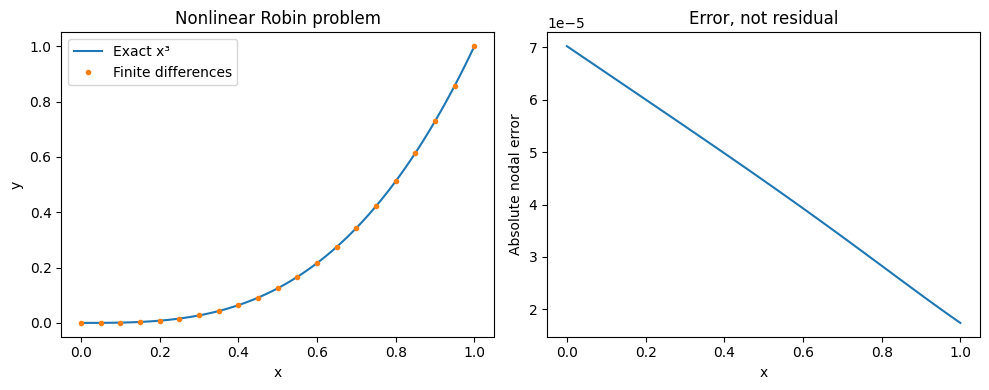

In [2]:
error = np.abs(result.y-result.x**3)
display(pd.DataFrame({'i': np.arange(81)[-10:], 'x': result.x[-10:],
                      'finite_difference': result.y[-10:],
                      'exact': result.x[-10:]**3, 'abs_error': error[-10:]}))
print('Maximum nodal error:', error.max())
assert error.max() < 7.1e-5
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(result.x, result.x**3, label='Exact x³')
axes[0].plot(result.x[::4], result.y[::4], '.', label='Finite differences')
axes[0].set(xlabel='x', ylabel='y', title='Nonlinear Robin problem')
axes[0].legend()
axes[1].plot(result.x, error)
axes[1].set(xlabel='x', ylabel='Absolute nodal error', title='Error, not residual')
fig.tight_layout()
plt.show()

## 5. Mesh refinement

Check the observed order $p=\log_2(E_h/E_{h/2})$. Under smoothness and stability,
the global finite-difference error is expected to be second order. Endpoint ghost
elimination can leave an $O(h)$ local ODE residual after division by $h^2$;
the global order is a property of the complete boundary scheme, which we check here.

In [3]:
rows = []
previous = None
for n in [20, 40, 80, 160]:
    sol = solve(n)
    assert sol.converged
    err = np.max(np.abs(sol.y-sol.x**3))
    rows.append({'n': n, 'nodes': n+1, 'max_error': err,
                 'observed_order': np.nan if previous is None else np.log2(previous/err)})
    previous = err
display(pd.DataFrame(rows))
assert 1.95 < rows[-1]['observed_order'] < 2.05

,n,nodes,max_error,observed_order
0,20,21,0.001124,NaN
1,40,41,0.000281,2.000520
2,80,81,0.000070,2.000130
3,160,161,0.000018,2.000032


## 6. Linear problems use one solve

For $y''=p(x)y'+q(x)y+r(x)$, the interior diagonals are
$-1-hp_i/2$, $2+h^2q_i$, $-1+hp_i/2$, with right-hand side $-h^2r_i$.
No Newton iteration is needed. Test the manufactured solution $y=e^x$ of
$y''=y$, $y'(0)+y(0)=2$, $-y'(1)+2y(1)=e$:

In [4]:
linear = linear_finite_difference(lambda x: 0, lambda x: 1, lambda x: 0,
    0, 1, Robin(1, 1, 2), Robin(-1, 2, np.e), n=80)
print('Linear maximum error:', np.max(np.abs(linear.y-np.exp(linear.x))))
print('Linear scaled residual:', linear.residual_norm)

Linear maximum error: 7.842397310975358e-05
Linear scaled residual: 5.3002741084995356e-12


## Further experiments

Change `method='crout'` to `method='dense'`, then compare solutions before
comparing runtimes. Try Dirichlet or Neumann data with a manufactured exact
solution. Full-step Newton is local: a different initial guess can find a different
root or fail. Convergence to one root does not prove uniqueness.

Continue with [comparing methods](05_comparing_methods.ipynb).

## References

- [Finite-difference theory and derivations](https://metodosnumericos.jonramos.dev/en/articulos/frontera-diferencias-finitas/)
- [Newton and nonlinear BVPs](https://metodosnumericos.jonramos.dev/en/articulos/frontera-diferencias-finitas-newton/)
- [NumPy linear solve](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html)